# 1. Data preparation

Loads the LimeSurvey export, normalizes text (apostrophes, blanks), turns `N/A` (question not reached) into missing values, derives grouping variables and saves `data/processed/survey_clean.csv`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.append(str(Path.cwd().parent))
from src import plots as P
from src.data import DERIVED_COLUMNS, clean_survey, load_raw
from src.plots import save_figure
from src.schema import resolve

RAW_PATH = Path("../data/raw/results-survey535447.csv")
PROCESSED_PATH = Path("../data/processed/survey_clean.csv")

## Load and clean

In [2]:
raw = load_raw(RAW_PATH)
df = clean_survey(raw)
sc = resolve(df.columns)  # raises if a question can no longer be found in the export
print(f"{raw.shape[0]} responses, {raw.shape[1]} columns, {int(df['completed'].sum())} completed")
df[[sc.response_id, *DERIVED_COLUMNS]].head()

44 responses, 57 columns, 26 completed


,Response ID,completed,role_group,pro_exp_group,ai_use_group,ai_stance_group,flex_group,similar_group
0,5,True,Management,Up to 10 years,Non-user,Unfavorable,High or complete,NaN
1,6,False,NaN,11–20 years,NaN,NaN,NaN,NaN
2,7,False,Software engineering,Up to 10 years,Daily / weekly,Favorable,NaN,NaN
3,8,False,NaN,NaN,NaN,NaN,NaN,NaN
4,9,True,Software engineering,Up to 10 years,Occasional,Unfavorable,Moderate,More similar


## Response flow

`Last page` is the last survey page a respondent saw; only submitted surveys have a `Date submitted`.

WindowsPath('C:/Users/andre/OneDrive - Chemische Werke Kluthe GmbH/Dokumente/Vorlesungen 8tes Semester/Bachelorarbeit/Analysis Survey/outputs/figures/response_flow.png')

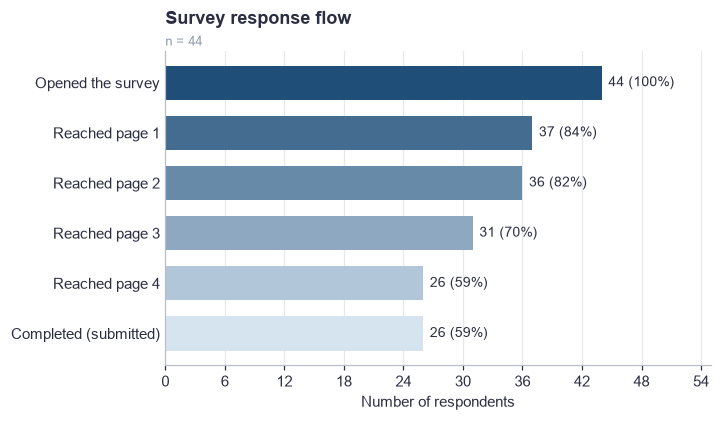

In [3]:
last_page = df[sc.last_page].fillna(0)
flow = pd.Series({
    "Opened the survey": len(df),
    "Reached page 1": int((last_page >= 1).sum()),
    "Reached page 2": int((last_page >= 2).sum()),
    "Reached page 3": int((last_page >= 3).sum()),
    "Reached page 4": int((last_page >= 4).sum()),
    "Completed (submitted)": int(df["completed"].sum()),
})
fig = P.bar_chart(flow, "Survey response flow", n=len(df), colors=P.sequential(len(flow))[::-1],
                  xlabel="Number of respondents")
save_figure(fig, "response_flow")

## Answers per question (completed surveys)

In [4]:
completed = df[df["completed"]]
questions = {
    "Education": sc.education, "Coding experience": sc.years_coding, "AI learning at work": sc.ai_learning,
    "Role": sc.role, "Professional experience": sc.years_pro, "Main language": sc.languages,
    "AI tool usage": sc.ai_use, "AI stance": sc.ai_stance, "AI job threat": sc.ai_threat,
    "Process flexibility": sc.flexibility, "Process factors (open text)": sc.process_factors,
    "Similar / different (choice)": sc.similar_choice, "Similar / different (open text)": sc.similar_comment,
    "Anything else (open text)": sc.anything_else,
}
answered = pd.Series({name: int(completed[col].notna().sum()) for name, col in questions.items()})
display(answered.to_frame("Answers").assign(Share=lambda t: (t["Answers"] / len(completed)).round(2)))

,Answers,Share
Education,26,1.00
Coding experience,26,1.00
AI learning at work,25,0.96
Role,26,1.00
Professional experience,26,1.00
Main language,25,0.96
AI tool usage,26,1.00
AI stance,26,1.00
AI job threat,26,1.00
Process flexibility,26,1.00


## Derived grouping variables

In [5]:
for col in DERIVED_COLUMNS[1:]:
    print(completed[col].value_counts(dropna=False).to_string(), "\n")

role_group
Software engineering    16
Management               5
Research & science       4
Other                    1 

pro_exp_group
Up to 10 years        10
11–20 years           10
More than 20 years     6 

ai_use_group
Daily / weekly    12
Non-user           8
Occasional         6 

ai_stance_group
Favorable           13
Neutral / unsure     7
Unfavorable          6 

flex_group
High or complete    10
Moderate            10
Limited              4
NaN                  2 

similar_group
More similar      17
More different     4
NaN                3
About the same     2 



## Save

In [6]:
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_PATH, index=False)
print(f"Saved {PROCESSED_PATH.resolve()}")

Saved C:\Users\andre\OneDrive - Chemische Werke Kluthe GmbH\Dokumente\Vorlesungen 8tes Semester\Bachelorarbeit\Analysis Survey\data\processed\survey_clean.csv
